In [2]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from tqdm import tqdm


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


In [4]:
  

# Inlet velocity
U_in = 1.0
Re=20.0

In [5]:

# Domain size
x_min, x_max = 0.0, 1.41     # streamwise direction
y_min, y_max = -0.5, 0.5    # vertical direction



# Cylinder
xc, yc = 0.2, 0.0   # center
R = 0.05            # radius
D=R*2

In [6]:
N_f = 20000  # collocation points

X_f = np.random.rand(N_f, 2)
X_f[:, 0] = X_f[:, 0] * (x_max - x_min) + x_min
X_f[:, 1] = X_f[:, 1] * (y_max - y_min) + y_min


In [7]:
def inside_cylinder(x, y):
    return (x - xc)**2 + (y - yc)**2 <= R**2


In [8]:
# --- Interior collocation points ---
N_f = 20000
X_f = np.random.rand(N_f,2)
X_f[:,0] = X_f[:,0]*(x_max - x_min) + x_min
X_f[:,1] = X_f[:,1]*(y_max - y_min) + y_min

# remove points inside cylinder
mask = ~inside_cylinder(X_f[:,0], X_f[:,1])
X_f = X_f[mask]


X_f = torch.tensor(X_f, dtype=torch.float32, requires_grad=True).to(device)

In [9]:
N_in = 1000
y_in = np.linspace(y_min, y_max, N_in)[:, None]
x_in = np.ones_like(y_in) * x_min


X_in = torch.tensor(np.hstack([x_in, y_in]), dtype=torch.float32).to(device)

In [10]:
H = y_max - y_min
u_in = 4 * U_in * (y_in - y_min) * (y_max - y_in) / H**2
v_in = np.zeros_like(u_in)
v_in = torch.tensor(v_in, dtype=torch.float32).to(device)
u_in = torch.tensor(u_in, dtype=torch.float32).to(device)

In [11]:
N_out = 1000
y_out = np.linspace(y_min, y_max, N_out)[:, None]
x_out = np.ones_like(y_out) * x_max

X_out = torch.tensor(np.hstack([x_out, y_out]), dtype=torch.float32).to(device)


In [12]:
N_wall = 3000
x_w = np.linspace(x_min, x_max, N_wall)[:, None]

y_bottom = np.ones_like(x_w) * y_min
y_top = np.ones_like(x_w) * y_max

X_wall = torch.tensor(
    np.vstack([
        np.hstack([x_w, y_bottom]),
        np.hstack([x_w, y_top])
    ]),
    dtype=torch.float32
).to(device)


In [13]:
N_cyl = 3000
theta = 2 * torch.pi * torch.rand((N_cyl, 1))
x_cyl = xc + R * torch.cos(theta)
y_cyl = yc + R * torch.sin(theta)

X_cyl = torch.cat([x_cyl, y_cyl], dim=1).to(device)

In [14]:
class PINN(nn.Module):
    def __init__(self, layers):
        super().__init__()
        self.activation = nn.Tanh()
        self.layers = nn.ModuleList(
            [nn.Linear(layers[i], layers[i+1]) for i in range(len(layers)-1)]
        )

    def forward(self, x):
        for layer in self.layers[:-1]:
            x = self.activation(layer(x))
        return self.layers[-1](x)


In [15]:
layers = [2, 64, 64, 64, 64, 3]  # (x,y) → (u,v,p)
model = PINN(layers).to(device)


In [16]:
def gradients(u, x):
    return torch.autograd.grad(
        u, x,
        grad_outputs=torch.ones_like(u),
        create_graph=True,
        retain_graph=True
    )[0]


In [17]:
def navier_stokes_residual(model, X):
    """
    X: tensor of shape (N, 2) -> (x, y)
    """
    X.requires_grad_(True)
    
    x = X[:, 0:1]
    y = X[:, 1:2]
    
    # Network prediction
    uvp = model(torch.cat([x, y], dim=1))
    u = uvp[:, 0:1]
    v = uvp[:, 1:2]
    p = uvp[:, 2:3]
    
    # First derivatives
    u_x = gradients(u, x)
    u_y = gradients(u, y)
    
    v_x = gradients(v, x)
    v_y = gradients(v, y)
    
    p_x = gradients(p, x)
    p_y = gradients(p, y)
    
    # Second derivatives
    u_xx = gradients(u_x, x)
    u_yy = gradients(u_y, y)
    
    v_xx = gradients(v_x, x)
    v_yy = gradients(v_y, y)
    
    # Continuity (mass conservation)
    f_cont = u_x + v_y
    
    # Momentum equations (non-dimensional)
    f_u = u * u_x + v * u_y + p_x - (1.0 / Re) * (u_xx + u_yy)
    f_v = u * v_x + v * v_y + p_y - (1.0 / Re) * (v_xx + v_yy)
    
    return f_cont, f_u, f_v



In [18]:
def loss_func(model):
    f_u, f_v, f_c = navier_stokes_residual(model, X_f)
    loss_pde = torch.mean(f_u**2) + torch.mean(f_v**2) + torch.mean(f_c**2)

    uvp_in = model(X_in)
    loss_in = torch.mean((uvp_in[:,0:1] - u_in)**2) \
              + torch.mean((uvp_in[:,1:2] - v_in)**2)

    p_out = model(X_out)[:,2:3]
    loss_out = torch.mean(p_out**2)

    uvp_wall = model(X_wall)
    loss_wall = torch.mean(uvp_wall[:,0:2]**2)

    uvp_cyl = model(X_cyl)
    loss_cyl = torch.mean(uvp_cyl[:,0:2]**2)

    # WEIGHTS (crucial)
    w_pde  = 1.0
    w_in   = 100.0
    w_out  = 50.0
    w_wall = 50.0
    w_cyl  = 50.0

    return (
        w_pde  * loss_pde +
        w_in   * loss_in +
        w_out  * loss_out +
        w_wall * loss_wall +
        w_cyl  * loss_cyl
    )


In [19]:
# Optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
num_epochs = 30000
loss_history = []

# Training loop with tqdm
from tqdm import trange
pbar = trange(num_epochs, desc="Training PINN")

for epoch in pbar:
    optimizer.zero_grad()
    
    # Total loss (physics + BCs)
    loss =loss_func(model) 
    
    # Backprop
    loss.backward()
    optimizer.step()
    
    loss_value = loss.item()
    loss_history.append(loss_value)
    
    pbar.set_postfix(loss=f"{loss_value:.3e}")

print("Training complete!")



Training PINN: 100%|██████████| 30000/30000 [23:39<00:00, 21.14it/s, loss=1.103e-02]

Training complete!


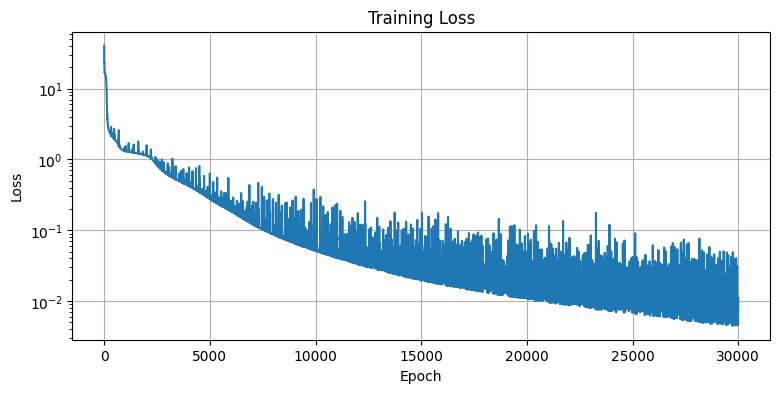

In [20]:
plt.figure(figsize=(9,4))
plt.plot(loss_history)
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.grid(True)
plt.show()


In [21]:
def get_pinn_field(model, xmin, xmax, ymin, ymax, N=60000):
    """
    Sample random points and evaluate PINN solution
    """
    # Random sampling
    x = np.random.uniform(xmin, xmax, N)
    y = np.random.uniform(ymin, ymax, N)

    # Remove cylinder points
    mask = (x - 0.2)**2 + (y - 0.0)**2 >= R**2
    x = x[mask]
    y = y[mask]

    # Predict
    XY = np.stack([x, y], axis=1)
    XY_t = torch.tensor(XY, dtype=torch.float32).to(device)

    with torch.no_grad():
        uvp = model(XY_t).cpu().numpy()

    u = uvp[:, 0]
    v = uvp[:, 1]
    p = uvp[:, 2]

    return [x, y, u, v, p]


In [22]:
def postProcess_PINN(xmin, xmax, ymin, ymax, field_PINN,
                     s=2, alpha=0.7, marker='o'):

    x, y, u, v, p = field_PINN

    fig, ax = plt.subplots(nrows=3, ncols=1, figsize=(4, 7))
    fig.subplots_adjust(hspace=0.25)

    fields = [(u, r'$u$ (m/s)'),
              (v, r'$v$ (m/s)'),
              (p, 'Pressure (Pa)')]

    for i, (val, title) in enumerate(fields):
        cf = ax[i].scatter(
            x, y, c=val,
            s=s,
            cmap='rainbow',
            alpha=alpha,
            edgecolors='none',
            marker=marker
        )

        # Cylinder (white)
        circle = plt.Circle((0.2, 0.0), R, color='white', zorder=10)
        ax[i].add_patch(circle)

        ax[i].set_aspect('equal')
        ax[i].set_xlim([xmin, xmax])
        ax[i].set_ylim([ymin, ymax])
        ax[i].set_xticks([])
        ax[i].set_yticks([])
        ax[i].set_title(title)

        for spine in ax[i].spines.values():
            spine.set_visible(False)

        fig.colorbar(cf, ax=ax[i], fraction=0.046, pad=0.04)

    plt.suptitle("PINN prediction – flow around cylinder", fontsize=12)
    plt.show()


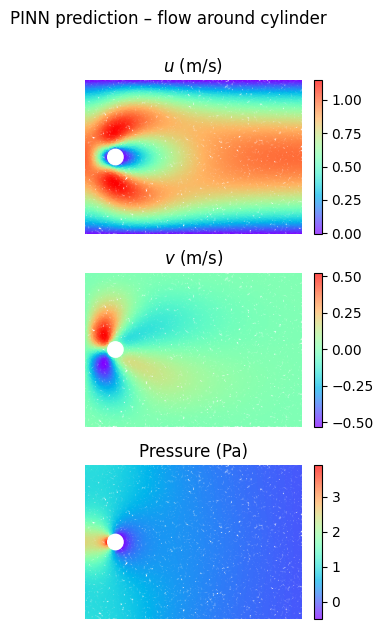

In [23]:
x_min, x_max = 0.0, 1.41     # streamwise direction
y_min, y_max = -0.5, 0.5  


field_PINN = get_pinn_field(model, x_min, x_max, y_min, y_max)

postProcess_PINN(x_min, x_max, y_min, y_max, field_PINN)


In [24]:
optimizer_lbfgs = torch.optim.LBFGS(
    model.parameters(),
    max_iter=1000,
    tolerance_grad=1e-6,
    tolerance_change=1e-8,
    history_size=50,
    line_search_fn="strong_wolfe"
)

def closure():
    optimizer_lbfgs.zero_grad()
    loss = loss_func(model)
    loss.backward()
    return loss

optimizer_lbfgs.step(closure)

tensor(0.0127, device='cuda:0', grad_fn=<AddBackward0>)

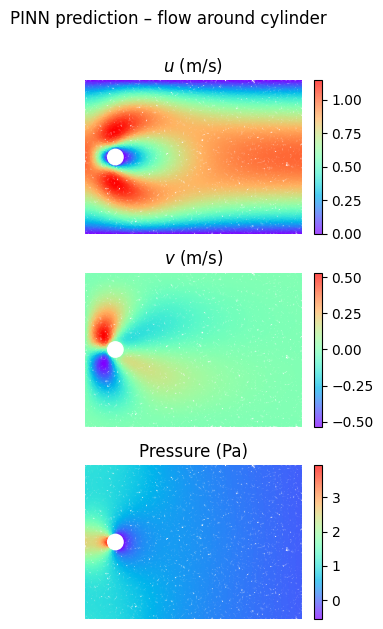

In [25]:
x_min, x_max = 0.0, 1.41     # streamwise direction
y_min, y_max = -0.5, 0.5  


field_PINN = get_pinn_field(model, x_min, x_max, y_min, y_max)

postProcess_PINN(x_min, x_max, y_min, y_max, field_PINN)

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

def postProcess_PINN1(xmin, xmax, ymin, ymax, field_PINN,
                     nx=300, ny=150):

    # Unpack scattered PINN field
    x, y, u, v, p = field_PINN


    # Structured grid (paper-like)
    xi = np.linspace(xmin, xmax, nx)
    yi = np.linspace(ymin, ymax, ny)
    X, Y = np.meshgrid(xi, yi)

    # Interpolation
    Ui = griddata((x, y), u, (X, Y), method='cubic')
    Vi = griddata((x, y), v, (X, Y), method='cubic')
    Pi = griddata((x, y), p, (X, Y), method='cubic')

    # Mask cylinder
    mask = (X - xc)**2 + (Y - yc)**2 <= R**2
    Ui[mask] = np.nan
    Vi[mask] = np.nan
    Pi[mask] = np.nan

    # Plot: Figure-3 style
    fig, ax = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)

    fields = [
        (Ui, r'(a) x-velocity $u$'),
        (Vi, r'(b) y-velocity $v$'),
        (Pi, r'(c) pressure $p$')
    ]

    for i, (val, title) in enumerate(fields):
        cf = ax[i].contourf(
            X, Y, val,
            levels=100,
            cmap='jet'
        )

        # Cylinder
        circle = plt.Circle((xc, yc), R, color='white', zorder=10)
        ax[i].add_patch(circle)

        ax[i].set_aspect('equal')
        ax[i].set_xlim(xmin, xmax)
        ax[i].set_ylim(ymin, ymax)
        ax[i].set_xticks([])
        ax[i].set_yticks([])
        ax[i].set_title(title)

        for spine in ax[i].spines.values():
            spine.set_visible(False)

        fig.colorbar(cf, ax=ax[i], fraction=0.046, pad=0.04)

    plt.show()


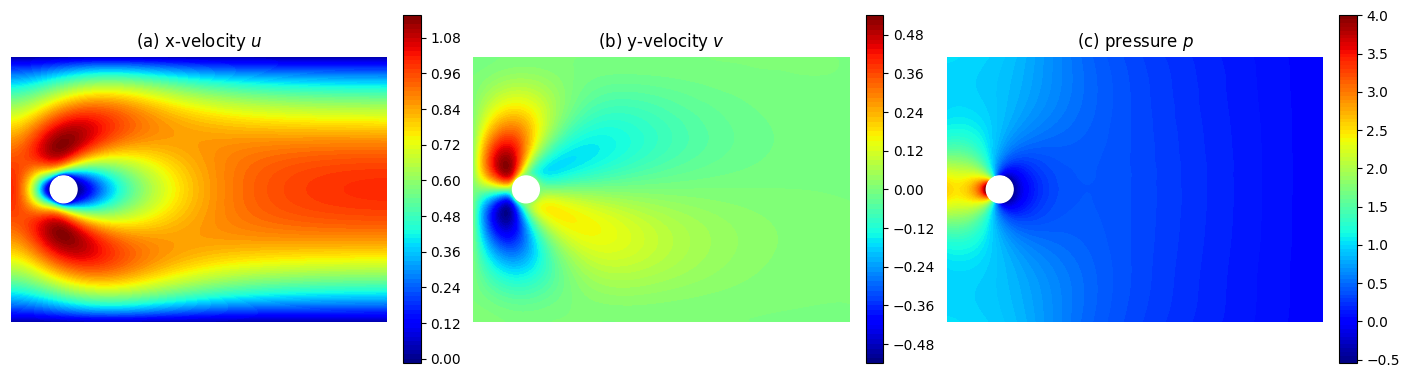

In [27]:
field_PINN = get_pinn_field(model, x_min, x_max, y_min, y_max)

postProcess_PINN1(x_min, x_max, y_min, y_max, field_PINN)

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

def postProcess_PINN_vorticity(xmin, xmax, ymin, ymax, field_PINN,
                               nx=600, ny=200, omega_max=3):

    # Unpack scattered PINN field
    x, y, u, v, _ = field_PINN

    # Cylinder geometry
    xc, yc = 0.2, 0.0

    # Structured grid (long wake)
    xi = np.linspace(xmin, xmax, nx)
    yi = np.linspace(ymin, ymax, ny)
    X, Y = np.meshgrid(xi, yi)

    # Interpolate velocity
    Ui = griddata((x, y), u, (X, Y), method='cubic')
    Vi = griddata((x, y), v, (X, Y), method='cubic')

    # Grid spacing
    dx = xi[1] - xi[0]
    dy = yi[1] - yi[0]

    # Vorticity ω = dv/dx - du/dy
    dVdx = np.gradient(Vi, dx, axis=1)
    dUdy = np.gradient(Ui, dy, axis=0)
    omega = dVdx - dUdy

    # Mask cylinder
    mask = (X - xc)**2 + (Y - yc)**2 <= R**2
    omega[mask] = np.nan

    # Plot
    fig, ax = plt.subplots(figsize=(10, 2.5))

    cf = ax.contourf(
        X, Y, omega,
        levels=200,
        cmap='seismic',
        vmin=-omega_max,
        vmax=omega_max
    )

    # Cylinder
    circle = plt.Circle((xc, yc), R, color='black', fill=False, linewidth=1.5)
    ax.add_patch(circle)


    ax.set_aspect('equal')
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title("Vorticity", fontsize=12)

    ax.set_xlabel("x")
    ax.set_ylabel("y")

    cbar = plt.colorbar(cf, ax=ax, fraction=0.025, pad=0.02)
    cbar.set_ticks([-omega_max, 0, omega_max])

    plt.show()


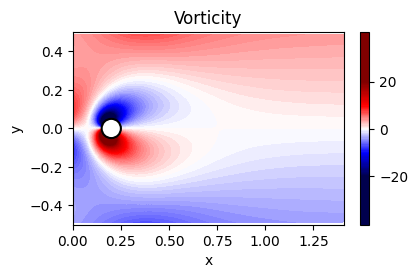

In [29]:
postProcess_PINN_vorticity(
    x_min,
    x_max,
    y_min,
    y_max,
    field_PINN=field_PINN,
    omega_max=20
)

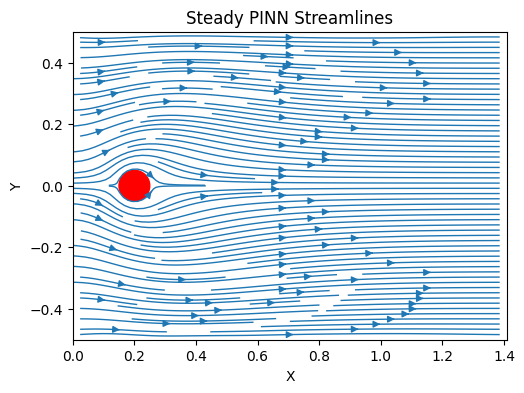

In [33]:
field_PINN = get_pinn_field(model, x_min, x_max, y_min, y_max)
x, y, u, v, _ = field_PINN
import matplotlib.pyplot as plt
import matplotlib.tri as tri
import numpy as np

triang = tri.Triangulation(x, y)
from scipy.interpolate import griddata

# Create structured grid
nx, ny = 300, 200
grid_x = np.linspace(x_min,x_max, nx)
grid_y = np.linspace(y_min, y_max, ny)
GX, GY = np.meshgrid(grid_x, grid_y)

# Interpolate
u_grid = griddata((x, y), u, (GX, GY), method='cubic')
v_grid = griddata((x, y), v, (GX, GY), method='cubic')
plt.figure(figsize=(8,4))

plt.streamplot(GX, GY, u_grid, v_grid,
               density=2, linewidth=1)

# Draw cylinder
circle = plt.Circle((0.2, 0.0), R, color='red')
plt.gca().add_patch(circle)

plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.gca().set_aspect('equal')

plt.title("Steady PINN Streamlines")
plt.xlabel("X")
plt.ylabel("Y")

plt.show()
